# Project 7 -- Oscar (Tzu Yang) Huang

**TA Help:** N/A

**Collaboration:** N/A

**Internet Resources:** Pandas, Stack Overflow, Kaggle, Seaborn, Metabase, GeeksForGeeks, Numpy, StackOverflow, Stack Exchange, Python, Youtube

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html: Learning what the drop function does and what the parameters are
- https://stackoverflow.com/questions/1712227/how-do-i-get-the-number-of-elements-in-a-list-length-of-a-list-in-python: Learning how to get the length of a list in python
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.columns.html: Learning how to access columns of a pandas dataframe using the "columns" functions in pandas
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iloc.html: Reviewing about iloc, which is the way I learnt how to segment the dataframe to get the independent variable X and dependent variable y, different from ".copy()" used
- https://www.kaggle.com/datasets/ksuqing/spotify-data-1986-2023/data?select=datos_merged_1986_2023.csv: Wanted to read a little into the dataset used for the assignment
- https://seaborn.pydata.org/generated/seaborn.histplot.html: Learning how to use the histogram funciton in seaborn
- https://seaborn.pydata.org/: Learning what seaborn is used for
- https://www.metabase.com/glossary/bin: Learning what a bin is used for in creating a histogram
- https://seaborn.pydata.org/archive/0.11/generated/seaborn.scatterplot.html: Learning how to use scatterplot function and its parameters
- https://seaborn.pydata.org/generated/seaborn.scatterplot.html: Learning the new version of seaborn's scatterplot function
- https://seaborn.pydata.org/archive/0.12/tutorial/regression.html: Learning if seaborn actually creates models and if it's suitable for creating models and if it is used more for visualization or so
- https://seaborn.pydata.org/generated/seaborn.regplot.html: Regression plot in the seaborn library
- https://www.geeksforgeeks.org/machine-learning/ml-linear-regression/: Learning how linear regression works
- https://numpy.org/doc/2.5/reference/generated/numpy.polyfit.html: Learning what type of least squares computation polyfit uses
- https://stackoverflow.com/questions/40017357/is-numpy-polyfit-with-1-degree-of-fitting-tls-or-ols: Learning that numpy is OLS, not TLS
- https://stats.stackexchange.com/questions/240142/fitting-a-straight-line-total-least-squares-or-ordinary-least-squares: Learning that numpy is OLS, not TLS
- https://realpython.com/linear-regression-in-python/: Learning about linear regression in python
- https://www.youtube.com/watch?v=ENnlSlvQHO0&t=5s: Learning about confidence interval

**ChatGPT, Gemini, Claude, etc:** N/A, all code is written by me by hand.

**OVERALL MESSAGE:** Any time that you used anything except your brain to solve the questions in these projects, you need to disclose such resources at the start of the project, with details about your usage of the tools.

**YOUR OWN WORK:** Even when you utilize other resources, do NOT just copy and paste.  Write all explanations in your own words, using several sentences in English, which are understandable and which you wrote (and did not just copy and paste).

## Question 1

In [1]:
import pandas as pd # Importing pandas library as pd (abbreviated for ease of access)

mySpotifyDF = pd.read_csv("/anvil/projects/tdm/data/spotify/linear_regression_popularity.csv") # Reading the linera regression 
# popularity of spotify songs dataset into "mySpotifyDF" dataframe using panda's read_csv function

mySpotifyDF.shape # Displaying the shape (number of rows and columns) of the dataframe to check initial size before dropping columns
# We get (1500, 37), meaning 1500 rows/data points and 37 columns

(1500, 37)

In [2]:
print(mySpotifyDF.columns) # Printing the columns of the mySpotifyDF dataframe before dropping some of them

Index(['Unnamed: 0.1', 'Unnamed: 0', 'track_id', 'track_name', 'popularity',
       'available_markets', 'disc_number', 'duration_ms', 'explicit',
       'track_number', 'href', 'album_id', 'album_name', 'album_release_date',
       'album_type', 'album_total_tracks', 'artists_names', 'artists_ids',
       'principal_artist_id', 'principal_artist_name', 'artist_genres',
       'principal_artist_followers', 'acousticness', 'analysis_url',
       'danceability', 'energy', 'instrumentalness', 'key', 'liveness',
       'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence',
       'year', 'duration_min'],
      dtype='object')


In [3]:
drop_cols = [
    "Unnamed: 0", "Unnamed: 0.1", "track_id", "track_name", "available_markets", "href",
    "album_id", "album_name", "album_release_date", "album_type",
    "artists_names", "artists_ids", "principal_artist_id",
    "principal_artist_name", "artist_genres", "analysis_url", "duration_min"] # Defining list of column names to be dropped

print(len(drop_cols)) # Printing the length of the list of drop_cols. We get 17 (columns)

mySpotifyDF = mySpotifyDF.drop(columns = drop_cols) # Defining the mySpotifyDF dataframe as one without the columns specified in 
# drop_cols by using the drop function in pandas that takes parameters of column specification, for example.

mySpotifyDF.shape # Getting the shape of the dataframe to check size after dropping columns. We get (1500, 20), which matches the 17 
# columns that are dropped from the initial 37 columns in the mySpotifyDF dataframe. This is good for cleaning the dataset for 
# irrelevant data points to be ignored.

17


(1500, 20)

In [4]:
print(mySpotifyDF.columns) # Printing columns of mySpotifyDF dataframe after dropping columns. We can see that 20 columns remain after.

Index(['popularity', 'disc_number', 'duration_ms', 'explicit', 'track_number',
       'album_total_tracks', 'principal_artist_followers', 'acousticness',
       'danceability', 'energy', 'instrumentalness', 'key', 'liveness',
       'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence',
       'year'],
      dtype='object')


### Below is short comment on the columns remaining after removing columns mentioned in drop_cols:
The columns remaining are "popularity" (popularity score of the song), "disc_number" (disc number of the song), "duration_ms" duration of song in milliseconds), "explicit" (whether the song is explicit), "track_number" (track number of the song), "album_total_tracks" (total number of tracks on the album of the song), "principal_artist_followers" (no. of followers of main artist), "acousticness" (confidence level of whether a track is more acoustic or not from 0 to 1). "danceability" (how danceable a song is from 0 to 1), "energy" (intensity and activity of a track from 0 to 1), "instrumentalness" (whether track has vocals from 0 to 1), "key" (estimated key of the track), "liveness" (whether there is an audient from 0 to 1), "loudness" (overall loudness of song in db), "mode" (modality of the track with 1 being major and 0 being minor), "speechiness" (presence of spoken word from 0 to 1), "tempo" (BPM of the song), "time_signature" (time signature of the song), "valence" (positivity of song from 0 to 1), and year (year released).

There is not much to be commented on right now, but the variables left make quite a lot of sense in trying to predict the popularity of a song, and I can immediately notice that the first column is popularity, making data analysis much easier since all columns after the first can be analyze to identify a trend with popularity of a song.

In [5]:
y = mySpotifyDF["popularity"].copy() # This creates a new variable called y (un-capitalized) which is the dependent variable of the 
# class which is the column of popularity in the mySpotifyDF dataframe. Copy creates a situation where it is isolated from the original
# dataframe so any accidental modifications is fine since this is a clone of the original dataframe. In the past, I would just use
# iloc to isolate the depedent variable by getting the indices, rather than column name, but this is also a method.

X = mySpotifyDF.drop(columns=["popularity"]).copy() # This creates a new variable called X (capitalized) which is the independent 
# variables (or sometimes variable) of the dataset, where it takes all remaining columns of mySpotifyDF after dropping the unneeded
# 17 columns in drop_cols and also drops the dependent variable column of popularity, then creating a clone of that.

print("\n================================ Visualizing y =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(y.head()) # By actually visualizing y dataframe, we can see that there is indices and their respective popularity, this is going to be
# used to match with the indices in X later on, but we want to isolate depdent and independent variables before any analysis. The actual
# result by printing the head we can see that song at index 0 has popularity of 67 (out of 100), song at index 1 has popularity of 70,
# song at index 2 has popularity of 75, song at index 3 has popularity of 65 and song at index 4 has popularity of 69. By getting the 
# top 5 results, sorted by index, we can pretty safely say that the column segmentation was quite successful.

print(y.shape) # If we print the shape of the y (dependent variable) dataframe and we get (1500,), which is 1500 rows and 1 column,
# which is really good for further data analysis as we can analyze how each variable contribute to y being a certain way and identify
# appropiate trends

print("\n================================ Visualizing X =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(X.head()) # If we actually visualize the X dataframe, we can see that popularity column is dropped, which is what we want and we 
# can now move on to further processing. We can see the the same songs from index 0-4 in y.head() has the rest of its independent 
# variables listed in X, such as key, loudness, speechiness, etc. 

print(X.shape)# If we print the shape of the X (independent variables) dataframe and we get (1500,19), which is 1500 rows and 19 column,
# which is really good for further data analysis as we can analyze how each variable contribute to y being a certain way and identify
# appropiate trends


================================ Visualizing y =================================

0    67
1    70
2    75
3    65
4    69
Name: popularity, dtype: int64
(1500,)

================================ Visualizing X =================================

   disc_number  duration_ms  explicit  track_number  album_total_tracks  \
0            1       355400     False             9                  14   
1            1       230549     False             2                  12   
2            1       115413     False             1                  12   
3            1       236946     False             1                  12   
4            1       195613     False             3                  12   

   principal_artist_followers  acousticness  danceability  energy  \
0                  48146159.0      0.271000         0.397   0.386   
1                   1403263.0      0.534000         0.571   0.438   
2                   3623467.0      0.000179         0.223   0.805   
3                    502744.

## Question 2

In [6]:
from sklearn.model_selection import train_test_split # Importing train_test_split module from the model_selection module of scikit-learn
# library. It is super useful to splitting dataset into train and test data. 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # This is the train test split module in 
# scikit-learn which is widely used in data science for data analaysis and data pre-processing. It is quite important to have both a 
# training and test set because we want to see if the model actually works well or if it has issues like overfitting or underfitting.
# Specifically in this line of code, the function returns 4 vectors in the order of independent variable X's training set, independent
# variable X's test set, dependent variable y's training set, and dependent variable y's test set. By taking the X and y we made in
# the last part, we get an 80/20 split of training and test data, which has a specific seed of 42 which I've seen a couple times. This
# means that the test split is standardized and processing and tests can be done over and over again with a specific data point. 
# Another key part of setting the seed is that if we just keep on creating randomized train_test_splits, our model creation might give
# rather inconsistent results.

print("\n================================ Shape of X_train =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(X_train.shape) # From getting the shape of the X_train vector, we get 1200 rows and 19 columns, which matches the 80/20 split
# we performed since 1500 * 0.8 = 1200.

print("\n================================ Head of X_train =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(X_train.head()) # There is not much for me to comment on here, besides the fact that it does look about right, in the sense that
# the rows are randomized, but I will note that the rows of the top 5 rows come in the order of index 382, 538, 1493, 1112, 324.
# We do quite correctly get the independent variables X here.


================================ Shape of X_train =================================

(1200, 19)

================================ Head of X_train =================================

      disc_number  duration_ms  explicit  track_number  album_total_tracks  \
382             1       223733     False             6                  13   
538             1       205066     False             8                  11   
1493            1       196186     False            10                  15   
1112            1       208866     False             7                  12   
324             1       231400     False             9                  16   

      principal_artist_followers  acousticness  danceability  energy  \
382                    3093464.0       0.00853         0.491   0.957   
538                     240252.0       0.17700         0.785   0.950   
1493                   8390210.0       0.05190         0.281   0.493   
1112                   7634319.0       0.01540         0.863 

In [7]:

print("\n================================ Shape of X_test =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(X_test.shape) # From getting the shape of the X_test vector, we get 300 rows and 19 columns, which matches the 80/20 split
# we performed since 1500 * 0.2 = 300.

print("\n================================ Head of X_test =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(X_test.head()) # Again, there is not much for me to comment on here, besides the fact that it does look about right, in the sense
# that the rows are randomized, but I will note that the rows of the top 5 rows come in the order of index 1116, 1368, 422, 413, 451.
# We do quite correctly get the independent variables X here.


================================ Shape of X_test =================================

(300, 19)

================================ Head of X_test =================================

      disc_number  duration_ms  explicit  track_number  album_total_tracks  \
1116            1       218264      True             1                   1   
1368            1       242666     False             9                  36   
422             1       310720      True             2                  17   
413             1       220893     False             3                  14   
451             1       222085      True             1                  19   

      principal_artist_followers  acousticness  danceability  energy  \
1116                   3005249.0        0.0171         0.684   0.630   
1368                   4402333.0        0.0310         0.513   0.770   
422                   25201820.0        0.0152         0.587   0.698   
413                     932439.0        0.4160         0.558   0

In [8]:

print("\n================================ Shape of y_train =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(y_train.shape) # From getting the shape of the y_train vector, we get 1200 rows and 1 column, which matches the 80/20 split
# we performed since 1500 * 0.8 = 1200.

print("\n================================ Head of y_train =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(y_train.head()) # Remember we noted that X_train had its top 5 rows come in the order of index 382, 538, 1493, 1112, 324, which
# indeed matches what we got in y_train as well, suggesting that the train_test_split was performed with quite a lot of success.
# We do quite correctly get the depdent variables y here.


================================ Shape of y_train =================================

(1200,)

================================ Head of y_train =================================

382     63
538     59
1493    67
1112    62
324     55
Name: popularity, dtype: int64


In [9]:
print("\n================================ Shape of y_test =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(y_test.shape) # From getting the shape of the y_train vector, we get 300 rows and 1 column, which matches the 80/20 split
# we performed since 1500 * 0.2 = 300.

print("\n================================ Head of y_test =================================\n") # Creating segmentation for more 
# clear visualization of the data

print(y_test.head()) # Again, there is also not much for me to comment on here as well, but I will draw the attention back to the fact
# that X_test's top 5 rows came in the order of index 1116, 1368, 422, 413, 451, which indeed matches what we get here, so we can
# quite safely conclude our operations up until now have been rather successful (our train_test_split was good).
# We do quite correctly get the depdent variables y here.


================================ Shape of y_test =================================

(300,)

================================ Head of y_test =================================

1116    79
1368    56
422     69
413     69
451     89
Name: popularity, dtype: int64


Text(0.5, 1.0, 'Popularity distribution of y_train vector')

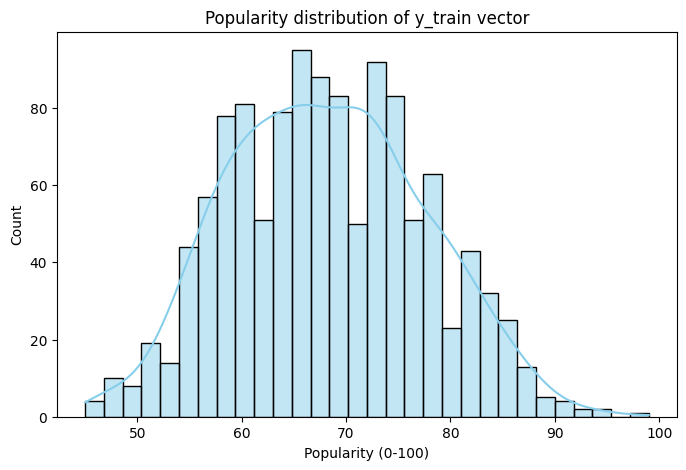

In [10]:
import matplotlib.pyplot as plt # Importing the pyplot module from matplot lib to do data visualization

import seaborn as sns # Importing seaborn, which very good for creating meaningful visualizations of data

plt.figure(figsize=(8,5)) # Creates the box/container for the graph to be in.

sns.histplot(y_train, bins=30, kde=True, color="skyblue") # Was going to use pyplot's histogram, but seaborn's histogram is much cleaner
# and provides more significant data representation. Bins is how many intervals there are in the graph, so meaning that a bin of 10
# would have less datapoints and have wider histogram boxes as it has to cover a wider range of data. We pass in the parameter of y_train
# as the vector/data to be represented. kde = true gives us a smooth curve that shows the overall trend, which is the blue curve we get
# in which we can observe that the distribution of the popularity follows a bell-curve which is to be expected from most data, with some 
# extremes being extremely popular and some being extremely unpopular, while most commonly occuring popularity lies around 60-70/100.
# color = "skyblue" sets the color of the histogram.

plt.xlabel("Popularity (0-100)") # Labeling the x-label of the graph as popularity

plt.ylabel("Count") # Labeling the y-label of the graph as count (or how often each popularity range showed up)

plt.title("Popularity distribution of y_train vector") # Labeling the title of the histogram graph as popularity distribution of y_train

## Question 3

In [11]:
y_train.describe() # Calling the describe function in pandas to get some significant info on the y_train vector.

count    1200.000000
mean       68.166667
std         9.315106
min        45.000000
25%        61.000000
50%        68.000000
75%        75.000000
max        99.000000
Name: popularity, dtype: float64

### Below is some comments on the distribution and features of the histogram in question 2:

By calling the describe function in pandas for our y_train vector, we can get severl interesting data points. Just as described above, the general trend of the songs do follow a bell normal curve distribution, slightly skewed to the right. One thing to notice here is that the lowest popularity in y_train is 45.000 (or 45 since it is originally expressed as an integer) which could suggest two things: 1) The people who created this dataset specifically picked some songs or albums to be analyzed, which leads to obscure songs not being included. We also notice that since it has a size of just 1500 songs, it doesn't really add up to the mass amount of data in entirety of spotify, so it could be a sample bias. 2) The people who created this dataset may have just tried to find 1500 random songs with the minimum threshold of popularity to be around 45, to prevent garbage/ai-generated songs being included in the dataset and skewing the results to the left and creating an inaccurate model for actually prediciting what makes a song popular. We can note that the mean is 68/100 which can kind of explain theory 2 we proposed just now, as medium to mid-high popularity songs can be a good data point to compare with super popular songs. The highest popularity is 99 and I'm assuming the 100/100 popularity is only reserved for the top % of songs in the entirety of spotify database, which also constantly fluctuates. One thing to point out is that the median is quite similar to the mean, with them being 68 and 68.17 respectively, building to the evidence that the dataset is mostly symmetrical, but slightly skewed to the right. I will also point out that with the bin being 30 instead of a number like 20, we can notice smaller details like the dips at around 62, 70 and 76, which could actually have led to the overall distribution being pulled down. Finally, the difference between 25% percentile and median and 75% percentile and median are the same, which can further build to the conclusion of a near symettric normal distribution.

## Question 4

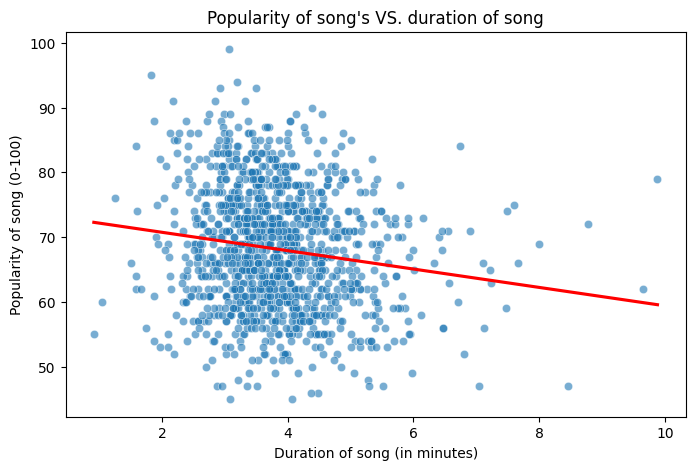

In [12]:
duration_min_train = X_train["duration_ms"] / 60000 # Defining a new variable called "duration_min_train" that converts the duration_ms
# column into minutes for training data. Since we want specifically the training set, this is an important step to isolate the variable
# we want to explore the relationship with the popularity of a song.

plt.figure(figsize=(8,5)) # Creates the box/container for the graph to be in.

sns.scatterplot(x=duration_min_train, y=y_train, alpha=0.6) # Using the seaborn library to create a scatterplot with the x-axis as the 
# duration of a song as defined in duration_min_train, which is the independent variable of the graph and with the y-axis as the 
# popularity of the song as defined in the y_train vector. Alpha = 0.6 sets the opacity of the points of the scatter plot, but one thing
# to note is that this is actually part of an older version of the seaborn library, so this should be considered moving on.

sns.regplot(x=duration_min_train, y=y_train, scatter=False, color="red", ci=None) # This creates a plot of the regression line by taking
# the same independent variable vector duration_min_train and dependent variable y_train. The scatter parameter as false makes it so 
# that the graph doesn't create overlapping scatter points, since we already did it one step above (I tested if I set scatter as 
# True, it becomes really messy since the both the fitted line and the scatter plots are red). color = "red" sets the color of the 
# linear regression line as red. "ci=none" sets it so that there is no confidence interval surrounding the fitted line. 

plt.xlabel("Duration of song (in minutes)") # Names the x-axis of graph as "Duration of song in minutes"

plt.ylabel("Popularity of song (0-100)") # Names the y-axis of graph as "Popularity of song (0-100)"

plt.title("Popularity of song's VS. duration of song") # Names the title of graph as "Popularity of song's VS. duration of song"

plt.show() # Actually displays the graph using pyplot

### Below is a short analysis of my understanding of confidence interval since I haven't explained it above:

In a dataset, most of the time, because of certain limitations (whether that's time, money, or otherwise), we are not able to do a statistical analysis on the entire population in which we want to observe, so we take a small sample of this said population i.e. the 1500 songs that was picked for this dataset. However, naturally, since the sample does not fully represent the actual population, the mean or median of the dataset will be slightly larger or smaller, depending on the specific sample. Therefore, it is important for us to know what is the possible range in which the true value lies, or in our case, what the actual linear regression line would look like for the the trend between duration of song and its popularity. Therefore, by setting the confidence interval to say 95, we want to create a band that contains the true line (of the trend of the entire population, which is something that is hard to get) around 95% of the time, which does explain why we see the band grow wider and wider as we increase the confidence value as we have to increase the range to increase the confidence in which we can state that yes, indeed, the actual trend line falls in this band.

### Below is a quick comment on something I noticed about using seaborn for linear regression:

One thing that I will note here is that I have noticed is that on Seaborn's website, they state that "seaborn is not itself a package for statistical analysis," so although the library does indeed create nice graphs and makes lines to fit a graph, we cannot actually use that model for number manipulation and doing statistical analysis on it. Therefore, it may be good to consider, moving on, to also use the numpy library alongside pandas to create actual models so we can predict and get more meaningful data.

## Question 5

### Below is the analysis of the linear regression and scatter plot made in question 4:

The overall relationship of the linear regression line that is fitted to the duration of the song vs. the popularity of a song has a negative correlation (meaning that as duration of song increases, popularity tends to decrease). One possible explanation of this is that songs that are popular tend to be quite replayable and the shorter it is, the more accessible it tends to be for the general audience. However, just as with any dataset, there are some outliers, such as the data point with popularity of ~80 that has a duration of ~10 minutes or a song that is just about 0.5 minutes long that is of popularity ~56, which could have potentially skewed the relationship, diminishing what the actual effect of duration of song has on its popularity. The regression line is created by finding the best fit linear line that minimizes the error/difference between the actual data and the predicted data/value. After reading some documentation in seaborn, it stated that under the hood, it uses the numpy polyfit function to create the linear regression model, in which it is noted that it uses ordinary least squares, a type of least squares method of calculation. In ordinary least squares, what the computation does is that it finds the difference between the predicted data point at a specific duration, and the actual point at a specific duration, then computing the vertical height difference, which is then squared and added together, in which the best model is the one with the lowest value of this ordinary least squared value. This essentially makes it so that the fitted line follows closely with the actual trend/relationship between duration of a song  and its respective popularity. The slope tells us how much popularity (from 0-100) changes with one unit increase of duration.

## Pledge

By submitting this work I hereby pledge that this is my own, personal work. I've acknowledged in the designated place at the top of this file all sources that I used to complete said work, including but not limited to: online resources, books, and electronic communications. I've noted all collaboration with fellow students and/or TA's. I did not copy or plagiarize another's work.

> As a Boilermaker pursuing academic excellence, I pledge to be honest and true in all that I do. Accountable together – We are Purdue.

https://www.purdue.edu/odos/osrr/honor-pledge/
